# Vehicle Silhouette Classification

Can you name a vehicle from its outline alone? Each sample is a single 2D silhouette of a vehicle (a bus, a van, an Opel Manta or a Saab 9000) reduced to **18 shape measurements** — compactness, circularity, aspect ratios, skewness about the axes, hollowness and more. The original 1980s research aimed at recognising vehicles from a single image so the model could be rotated to match. Classify the vehicle type from its silhouette statistics.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# UCI serves this dataset as a ready CSV at the dataset's data_url
df = pd.read_csv(io.BytesIO(download('https://archive.ics.uci.edu/static/public/149/data.csv')))
print('As shipped:', df.shape)
# One row of UCI's merged CSV is corrupted (its values are shifted and its 'class' reads 204); drop it
df = df[df['class'].isin(['bus', 'opel', 'saab', 'van'])].reset_index(drop=True)
print('After dropping the corrupted row:', df.shape)
df.head(3)

As shipped: (846, 19)
After dropping the corrupted row: (845, 19)


,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PR.AXIS ASPECT RATIO,MAX.LENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PR.AXIS RECTANGULARITY,MAX.LENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO,class
0,95.0,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91.0,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104.0,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab


In [2]:
X = df.drop(columns=['class']); y = df['class']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.7358
Logistic Regression accuracy: 0.8208
              precision    recall  f1-score   support

         bus       0.92      0.98      0.95        55
        opel       0.55      0.43      0.48        53
        saab       0.52      0.56      0.54        54
         van       0.92      0.98      0.95        50

    accuracy                           0.74       212
   macro avg       0.73      0.74      0.73       212
weighted avg       0.72      0.74      0.73       212



MAX.LENGTH ASPECT RATIO             0.113347
SCALED VARIANCE ALONG MINOR AXIS    0.080451
MAX.LENGTH RECTANGULARITY           0.073150
ELONGATEDNESS                       0.067653
SCATTER RATIO                       0.066384
DISTANCE CIRCULARITY                0.061671
SCALED VARIANCE ALONG MAJOR AXIS    0.058989
COMPACTNESS                         0.057082
HOLLOWS RATIO                       0.055248
SKEWNESS ABOUT MAJOR AXIS           0.053635
PR.AXIS ASPECT RATIO                0.049608
CIRCULARITY                         0.044108
dtype: float64


<Axes: title={'center': 'Which shape measurements identify the vehicle?'}>

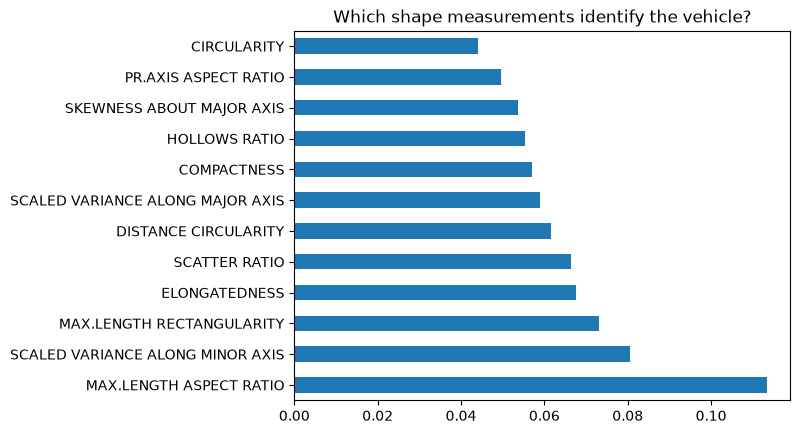

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(12))
imp.head(12).plot(kind='barh', title='Which shape measurements identify the vehicle?')